# Lab Regressions
I noticed a couple weird things with the labs and want to investigate further. For example, vitamin D2 only has 7 observations that are numbers other than 4.0. Weird.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import arivale_data_interface as adi
# apply settings so the lib knows where the data is
adi.apply_isb_config()

# For regressions
from regression_functions import *
from rich.progress import track
from statsmodels.formula.api import ols
from statsmodels.stats.multitest import multipletests

# Read in abx and health history data

## OG cohort

In [2]:
abx_covar = pd.read_csv("data/abx_recency_covariates_all_trimmed.csv")
abx_covar.drop(columns='GLYCOHEMOGLOBINA1C', inplace=True)

In [3]:
abx_covar.days_in_program.dtype

dtype('float64')

# Import and clean up labs

In [4]:
labs = adi.get_snapshot('chemistries', clean=True) # Not sure the clean param is working
labs.columns = labs.columns.str.replace(', ', '_')
labs.columns = labs.columns.str.replace('-', '_')
labs.columns = labs.columns.str.replace('/', '_')
labs.columns = labs.columns.str.replace(' ', '')
labs.columns = labs.columns.str.replace('(', '_')
labs.columns = labs.columns.str.replace(')', '_')
labs.head()

,public_client_id,vendor,vendor_observation_id,observation_id,reflexive,fasting,days_in_program,days_since_first_call,days_since_first_draw,month,...,VITAMIND3_25_OH,VLDLLDLPARTICLENUMBER,VLDLPARTICLENUMBER,VLDLSIZEPERCENTILE,VLDLTRIGLYCERIDES,WHITECELLCOUNT,ZINC,ZINC_RBC,leptin,zinc_plasma_or_serum
0,01000261,Quest,YH289668,10271,False,TRUE,65,-9.0,0,Jan,...,58.0,NaN,NaN,NaN,NaN,5.9,980.0,9.8,NaN,NaN
1,01000261,LCA,B0040998784,65656,False,TRUE,198,124.0,133,May,...,NaN,1753.0,45.5,48.9,69.1,4.9,1410.0,NaN,NaN,NaN
2,01001298,LCA,AV27365801,2837393,False,TRUE,7,0.0,0,Sep,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,01001467,LCA,AV29176623,2500980,False,TRUE,15,1.0,0,Jun,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,01001467,LCA,AV29431391,3306809,True,TRUE,223,209.0,208,Jan,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [5]:
labs.drop(columns=['GFR_MDRD', 'GFR_MDRD_AFRICANAM'], inplace=True)

In [6]:
# Drop users that aren't fasting for the blood draw
labs = labs[labs['fasting']=="TRUE"]

In [7]:
# Change type to be compatible for merge
labs.days_in_program = labs.days_in_program.astype('float64')
labs.days_in_program.dtype

dtype('float64')

## Assign lab features and merge

In [8]:
lab_features = labs.iloc[:,12:].columns.tolist()

In [9]:
labs = labs.sort_values(by="days_in_program")
abx_covar = abx_covar.sort_values(by="days_in_program")

# Merge with measure
labs_merged = pd.merge_asof(
    abx_covar, labs, 
    by="public_client_id", 
    on="days_in_program", 
    direction="nearest", 
    tolerance=30.0).dropna(subset='abx_recency')

labs_merged = labs_merged.drop_duplicates(subset='public_client_id')

In [10]:
# Check for duplicates again
dup_folks = labs_merged[labs_merged.public_client_id.duplicated()].public_client_id.to_list()
labs_merged[labs_merged.public_client_id.isin(dup_folks)].sort_values(by='public_client_id')

,public_client_id,PC1,PC2,PC3,PC4,PC5,days_in_program,meds_blood_sugar,meds_cholesterol,abx_recency,...,VITAMIND3_25_OH,VLDLLDLPARTICLENUMBER,VLDLPARTICLENUMBER,VLDLSIZEPERCENTILE,VLDLTRIGLYCERIDES,WHITECELLCOUNT,ZINC,ZINC_RBC,leptin,zinc_plasma_or_serum


In [11]:
labs_merged[lab_features].isna().all(axis=1).sum()

291

Looks like there are 294 people who don't have any lab values :o

In [12]:
labs_merged = labs_merged.dropna(subset=lab_features, how='all')

## Drop super sparse lab tests

In [13]:
bad = labs_merged[lab_features].isnull().sum() / labs_merged[lab_features].shape[0] > 0.9
bad[bad == True]
lab_features_test = bad[~bad].index
labs_covar_dx = labs_merged.drop(columns=bad[bad].index)
labs_covar_dx.shape

(2351, 132)

In [14]:
labs_covar_dx.abx_recency.value_counts()

abx_recency
none      1456
twelve     516
three      379
Name: count, dtype: int64

## Check QUICKI and HOMA_IR values

Previously I saw something fishy about the QUICKI values being really low across the board. For QUICKI, higher is better and generally > 0.39 (though some say 0.35) is good. Lower values would indicate increased insulin resistance. The values below are very strange, they would seem to suggest severe insulin resistance. 

In [15]:
labs_covar_dx.QUICKI.describe()

count    493.000000
mean       0.148099
std        0.012296
min        0.104319
25%        0.140172
50%        0.147668
75%        0.155372
max        0.198533
Name: QUICKI, dtype: float64

In [16]:
# labs_covar_dx[labs_covar_dx.QUICKI.notna()].vendor.value_counts()

Perhaps it's due to the vendor being different? Maybe they used a different equation or have different units for insulin or glucose? Let's take a look. 

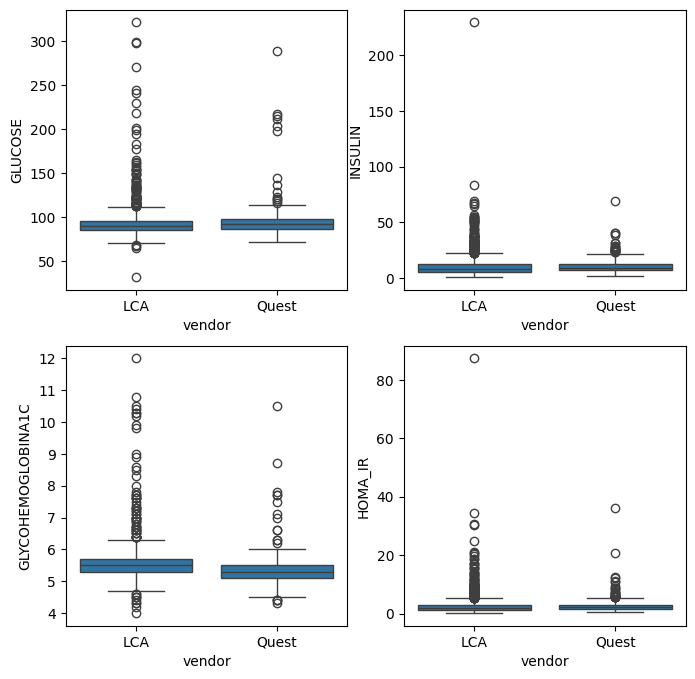

In [17]:
bs_labs_check = ['GLUCOSE', 'INSULIN', 'GLYCOHEMOGLOBINA1C', 'HOMA_IR']
my_pal = {'none': "#007ea7", 'twelve': "#80ced7", 'three': '#ccdbdc'}

fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

for i, lab in enumerate(bs_labs_check):
    sns.boxplot(data=labs_covar_dx, x='vendor', y=lab, ax=axes[i])

Okay given the Quest folks have potentially lower A1C, I think the reason we see the low QUICKI is probably not because of severe IR, but rather a difference in how it's calculated. Let's look at the QUICKI and HOMA_IR formulas I can find online:
- $\text{HOMAIR} = \frac{(I \text{uU/mL})*(G \text{mmol/L})}{22.5}$; expected values less than 1 is good, over 2 may be IR (so lower better)

- $\text{QUICKI} = \frac{1}{log(I \text{uU/mL}) + log(G \text{mg/dL})}$; no universally accepted value though above 0.357 is better (higher better)

According to the labcorp AND Quest websites, the glucose units are mg/dL and seem to be within normal range. Insulin units for both are uIU/mL which will work without any tranformation in these equations. 

In [18]:
labs_covar_dx.HOMA_IR.describe() # Seems a little high to me...

count    2351.000000
mean        2.604268
std         3.150688
min         0.177778
25%         1.245679
50%         1.872593
75%         2.912099
max        87.304691
Name: HOMA_IR, dtype: float64

In [19]:
quest = labs_covar_dx[labs_covar_dx['vendor'] == 'Quest']
labcorp = labs_covar_dx[labs_covar_dx['vendor'] == 'LCA']

In [20]:
quest.HOMA_IR.describe()

count    498.000000
mean       2.640592
std        2.324803
min        0.380247
25%        1.538889
50%        2.128395
75%        3.080247
max       35.948148
Name: HOMA_IR, dtype: float64

In [21]:
labcorp.HOMA_IR.describe()

count    1853.000000
mean        2.594505
std         3.338457
min         0.177778
25%         1.172840
50%         1.762469
75%         2.831111
max        87.304691
Name: HOMA_IR, dtype: float64

The above seems a little high to me, and it's not related to the vendors. Let's recalculate both QUICKI and HOMA_IR. 

In [22]:
labs_covar_dx.drop(columns=['QUICKI'], inplace=True) 
# No need to drop HOMA_IR bc it was calculated correctly

In [23]:
labs_covar_dx.loc[:, "QUICKI"] = 1 / (
    np.log10(labs_covar_dx["INSULIN"]) + np.log10(labs_covar_dx["GLUCOSE"])
)

labs_covar_dx.QUICKI

1       0.305599
2       0.486982
3       0.335478
4       0.378068
5       0.357227
          ...   
2637    0.399503
2638    0.342845
2639    0.324876
2640    0.358640
2641    0.317141
Name: QUICKI, Length: 2351, dtype: float64

In [24]:
((labs_covar_dx["INSULIN"] * labs_covar_dx["GLUCOSE"]) / 405).describe() # Looks like a combo of the above

count    2351.000000
mean        2.604268
std         3.150688
min         0.177778
25%         1.245679
50%         1.872593
75%         2.912099
max        87.304691
dtype: float64

Well turns out the HOMA_IR values were calculated correctly, perhaps a bit higher than expected. However, we did fix the QUICKI calculation issue!

## Check which lab tests provided by each vendor

In [25]:
len(lab_features_test)

101

There were a total of 126 lab tests that were in the snapshot. I dropped tests where over 90% of rows/samples were null. However, some tests were provided only by one vendor.

In [26]:
#quest.iloc[:, 30:].columns
quest[lab_features_test]

,A_GRATIO,ADIPONECTIN_SERUM,ALAT_SGPT_,ALBUMIN,ALKALINEPHOSPHATASE,ANTIOXIDCAP_TOTAL,ARACHIDONICACID,ARSENIC_BLOOD,ASAT_SGOT_,BASOPHILS,...,TRIGLYCERIDES,TriglycerideHDLRatio,UREANITROGEN,URICACID,VITAMIND_25_OHTOT,VITAMIND2_25_OH,VITAMIND3_25_OH,WHITECELLCOUNT,ZINC,ZINC_RBC
5,1.8,9.9,20.0,4.5,49.0,1373.2,NaN,2.0,22.0,0.2,...,71.0,1.290909,14.0,4.9,23.0,4.0,23.0,4.6,1070.0,10.7
15,1.6,15.4,15.0,4.1,47.0,1787.2,7.4,3.0,19.0,0.4,...,119.0,1.451220,9.0,4.4,25.0,4.0,25.0,5.1,1140.0,11.4
29,2.0,5.1,14.0,4.3,68.0,916.3,8.8,2.0,13.0,0.0,...,72.0,1.161290,16.0,4.8,29.0,4.0,29.0,6.3,1270.0,12.7
43,1.8,24.2,15.0,4.6,80.0,1040.7,4.7,3.0,33.0,0.3,...,52.0,0.481481,17.0,5.1,70.0,4.0,70.0,5.4,870.0,8.7
52,1.4,11.2,16.0,4.1,88.0,906.7,7.6,2.0,14.0,0.2,...,119.0,1.506329,21.0,5.4,27.0,4.0,27.0,6.1,1170.0,11.7
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2581,1.7,9.2,18.0,4.5,42.0,1138.1,7.1,2.0,15.0,0.2,...,113.0,2.306122,11.0,4.7,29.0,4.0,29.0,6.0,1280.0,12.8
2583,1.9,6.4,15.0,5.0,54.0,1496.5,11.2,2.0,22.0,0.4,...,69.0,0.696970,13.0,4.3,28.0,4.0,28.0,5.4,710.0,7.1
2592,2.0,5.3,24.0,4.4,99.0,1215.4,7.3,5.0,24.0,0.6,...,75.0,1.271186,12.0,5.9,25.0,8.0,17.0,3.2,1130.0,11.3
2602,2.0,4.0,33.0,4.6,49.0,1409.2,8.1,2.0,28.0,0.4,...,107.0,2.057692,20.0,6.8,30.0,4.0,30.0,7.2,960.0,9.6


In [27]:
quest[lab_features_test].isna().sum() / quest[lab_features_test].shape[0]

A_GRATIO               0.000000
ADIPONECTIN_SERUM      0.002008
ALAT_SGPT_             0.000000
ALBUMIN                0.000000
ALKALINEPHOSPHATASE    0.000000
                         ...   
VITAMIND2_25_OH        0.002008
VITAMIND3_25_OH        0.002008
WHITECELLCOUNT         0.000000
ZINC                   0.002008
ZINC_RBC               0.002008
Length: 101, dtype: float64

**Find tests not offered by Quest**

In [28]:
len(quest[lab_features_test].isna().all()[quest[lab_features_test].isna().all()])
# Not offered by quest

11

In [29]:
not_offered_quest = (quest[lab_features_test].isna().all()[quest[lab_features_test].isna().all()]).index

In [30]:
len(not_offered_quest) # This changes later bc we drop LDL_SIZE and that goes to shared

11

Okay above it looks like several tests were not offered, including leptin or omega_3_total.

**Find tests not offered by Labcorp**

In [31]:
len(labcorp[lab_features_test].isna().all()[labcorp[lab_features_test].isna().all()])
# not offered by labcorp

21

In [32]:
not_offered_labcorp = (labcorp[lab_features_test].isna().all()[labcorp[lab_features_test].isna().all()]).index

## Now look at the lab values that are shared and assess for bimodal distributions?

In [33]:
shared_labs = list(set(lab_features_test) - set(not_offered_labcorp) - set(not_offered_quest))

In [34]:
len(shared_labs) # This increases to 70 later

69

<Axes: xlabel='BMI_CALC', ylabel='GLUTATHIONE_TOTAL'>

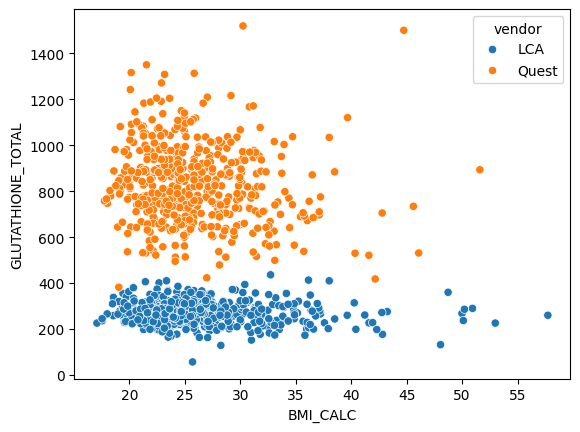

In [35]:
sns.scatterplot(data=labs_covar_dx, x='BMI_CALC',y='GLUTATHIONE_TOTAL', hue='vendor')

In [36]:
# formula = ("FOLICACID_SERUM ~  C(abx_recency) + age + sex + BMI_CALC + centered_eGFR + C(meds_blood_sugar) + C(meds_cholesterol) + PC1 + PC2 + PC3 + PC4 + PC5")
# fitted = ols(formula, data=labcorp).fit()
# fitted.summary()

Most of them seem to scatter in same areas which makes me think the units are the same/having the vendor as a covariate would be sufficient to correct. 
- Zinc still overlaps, but seems to definitely have a batch effect.
- Glutathione definitely uses different units!
- EPA_AA only has one count as labcorp, that seems to be a mistake? Although it seems to fall in the range of the Quest counts anyway.
- Folic acid looks suspicious as there seems to be an upper limit of detection? It stops at 20 whereas Quest goes higher.

In [37]:
quest.FOLICACID_SERUM.describe()

count    498.000000
mean      22.131928
std        9.957245
min        4.500000
25%       15.400000
50%       19.800000
75%       28.000000
max       97.900000
Name: FOLICACID_SERUM, dtype: float64

In [38]:
labcorp.FOLICACID_SERUM.describe()

count    1783.000000
mean       15.041447
std         4.151470
min         2.100000
25%        11.900000
50%        15.400000
75%        19.200000
max        20.000000
Name: FOLICACID_SERUM, dtype: float64

## Now look at the *data* for the lab tests that are unique to each provider

### Unique to Quest

In [39]:
labs_covar_dx[not_offered_labcorp].isna().sum() / labs_covar_dx[not_offered_labcorp].shape[0]

ANTIOXIDCAP_TOTAL      0.788601
ARSENIC_BLOOD          0.788601
BILIRUBIN_DIRECT       0.788175
BILIRUBIN_INDIRECT     0.788175
COPPER_RBC             0.788601
HDLLARGE               0.788175
LACTICDEHYDROGENASE    0.788175
LDLMEDIUM              0.788175
LDLPEAKSIZE            0.788175
MANGANESE_SERUM        0.788175
MPV                    0.788175
NEUTROPHIL_SEGS        0.788175
NEUTROPHILSABSOLUTE    0.788175
PAI_1ANTIGEN_QNT       0.788175
PHOSPHORUSINORGANIC    0.788175
PLATELETCOUNT          0.788175
SELENIUM_SERUM         0.788175
SUPEROXDISMUTSOD       0.788175
VITAMIND2_25_OH        0.788601
VITAMIND3_25_OH        0.788601
ZINC_RBC               0.788601
dtype: float64

In [40]:
# Quest unique labs
labs_covar_dx[not_offered_labcorp].describe().T

,count,mean,std,min,25%,50%,75%,max
ANTIOXIDCAP_TOTAL,497.0,1301.041247,420.471429,576.20,988.500,1226.700,1511.80,3338.50
ARSENIC_BLOOD,497.0,2.909457,2.323150,2.00,2.000,2.000,3.00,31.00
BILIRUBIN_DIRECT,498.0,0.143373,0.065051,0.00,0.100,0.100,0.20,0.50
BILIRUBIN_INDIRECT,498.0,0.557831,0.229488,0.20,0.400,0.500,0.60,2.20
COPPER_RBC,497.0,0.653662,0.111698,0.40,0.580,0.630,0.70,1.35
HDLLARGE,498.0,6180.628514,1687.503008,2868.00,4940.750,5864.000,7151.25,12577.00
LACTICDEHYDROGENASE,498.0,137.574297,22.884794,69.00,121.000,135.000,151.00,232.00
LDLMEDIUM,498.0,243.734940,91.630667,48.00,175.250,229.000,292.75,697.00
LDLPEAKSIZE,498.0,221.037149,4.958476,200.60,218.600,221.100,224.20,233.80
MANGANESE_SERUM,498.0,0.633133,0.196771,0.50,0.500,0.600,0.70,3.10


<Axes: xlabel='VITAMIND2_25_OH', ylabel='age'>

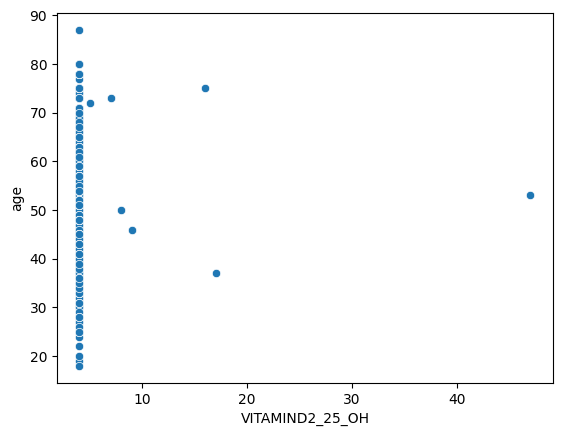

In [41]:
sns.scatterplot(data=labs_covar_dx, x='VITAMIND2_25_OH', y='age')

In [42]:
labs_covar_dx.drop(columns='VITAMIND2_25_OH', inplace=True)
not_offered_labcorp = not_offered_labcorp.drop('VITAMIND2_25_OH')

In [43]:
len(not_offered_labcorp)

20

### Unique to labcorp

In [44]:
len(not_offered_quest)

11

In [45]:
labs_covar_dx[not_offered_quest].isna().sum() / labs_covar_dx[not_offered_quest].shape[0]

DPA                             0.212250
HDLPARTICLENUMBER               0.212675
IMMATUREGRANULOCYTES            0.219056
IMMATUREGRANULOCYTESABSOLUTE    0.219056
LDL_SIZE                        0.216078
LINOLEIC_ACID                   0.212250
LPIR_SCORE                      0.212675
MAGNESIUM_SERUM                 0.217780
OMEGA_3_TOTAL                   0.212250
OMEGA_6_TOTAL                   0.212250
OXLDL                           0.225861
dtype: float64

In [46]:
labs_covar_dx[not_offered_quest].describe().T
# Distributions look reasonable

,count,mean,std,min,25%,50%,75%,max
DPA,1852.0,1.090443,0.225784,0.1,0.9,1.1,1.2,2.3
HDLPARTICLENUMBER,1851.0,34.394057,5.980733,16.0,30.2,34.2,38.2,59.4
IMMATUREGRANULOCYTES,1836.0,0.022331,0.158474,0.0,0.0,0.0,0.0,2.0
IMMATUREGRANULOCYTESABSOLUTE,1836.0,0.000708,0.008387,0.0,0.0,0.0,0.0,0.1
LDL_SIZE,1843.0,21.118068,0.541747,19.5,20.8,21.2,21.5,22.6
LINOLEIC_ACID,1852.0,25.817387,2.694320,14.6,24.1,25.8,27.6,34.5
LPIR_SCORE,1851.0,41.792545,19.621697,25.0,25.0,33.0,55.0,100.0
MAGNESIUM_SERUM,1839.0,2.025014,0.154634,1.3,1.9,2.0,2.1,3.4
OMEGA_3_TOTAL,1852.0,4.449946,1.224915,1.8,3.6,4.2,5.1,11.8
OMEGA_6_TOTAL,1852.0,39.940065,3.004055,23.7,38.1,40.2,41.9,50.2


Omg I can't believe I missed all the 0s in the granuloctye columns! Drop those as they have few real observations.

In [47]:
labs_covar_dx['IMMATUREGRANULOCYTES'].value_counts()

IMMATUREGRANULOCYTES
0.0    1798
1.0      35
2.0       3
Name: count, dtype: int64

In [48]:
labs_covar_dx['IMMATUREGRANULOCYTESABSOLUTE'].value_counts()

IMMATUREGRANULOCYTESABSOLUTE
0.0    1823
0.1      13
Name: count, dtype: int64

In [49]:
labs_covar_dx.drop(columns=['IMMATUREGRANULOCYTES', 'IMMATUREGRANULOCYTESABSOLUTE'], inplace=True)
not_offered_quest = not_offered_quest.drop(['IMMATUREGRANULOCYTES', 'IMMATUREGRANULOCYTESABSOLUTE'])

## Try fixing glutathione prior to regresssions
According to their websites the reference ranges are: 
- Labcorp: 176 - 323 ug/mL
- Quest: 373-838 uM

This is in line with what we see in the data. The values for Quest pretty much start where the values for labcorp end. Glutathione has a molecular weight of approximately 307.32 g/mol, so we can recalculate the levels to match. 1ug/mL is ~ 3.254 uM. 

In [50]:
quest.GLUTATHIONE_TOTAL.describe()

count     495.000000
mean      832.987879
std       169.336033
min       382.000000
25%       721.500000
50%       823.000000
75%       935.000000
max      1519.000000
Name: GLUTATHIONE_TOTAL, dtype: float64

In [51]:
labcorp.GLUTATHIONE_TOTAL.describe()

count    453.000000
mean     271.370861
std       50.303365
min       57.000000
25%      236.000000
50%      271.000000
75%      307.000000
max      436.000000
Name: GLUTATHIONE_TOTAL, dtype: float64

**First test to see if this fixes the separation; aka test the hypothesis that the unit was driving the difference**

Doing this in the quest data only before fixing it in the larger dataframe

In [52]:
glutathione_convert = quest[['public_client_id', 'GLUTATHIONE_TOTAL']].copy()
glutathione_convert.set_index('public_client_id', inplace=True)

In [53]:
MW_GSH = 307.32

In [54]:
glutathione_convert["GLUTATHIONE_CONVERT"] = glutathione_convert['GLUTATHIONE_TOTAL'] * MW_GSH / 1000

In [55]:
glutathione_convert.GLUTATHIONE_CONVERT.describe()
# This seems much more similar to the lapcorp ones!

count    495.000000
mean     255.993835
std       52.040350
min      117.396240
25%      221.731380
50%      252.924360
75%      287.344200
max      466.819080
Name: GLUTATHIONE_CONVERT, dtype: float64

**Now use a mask to change in the larger dataframe**

In [56]:
quest_mask = labs_covar_dx['vendor'] == 'Quest'
labs_covar_dx.loc[quest_mask, 'GLUTATHIONE_TOTAL'] = labs_covar_dx.loc[quest_mask, 'GLUTATHIONE_TOTAL'] * MW_GSH / 1000

<Axes: xlabel='BMI_CALC', ylabel='GLUTATHIONE_TOTAL'>

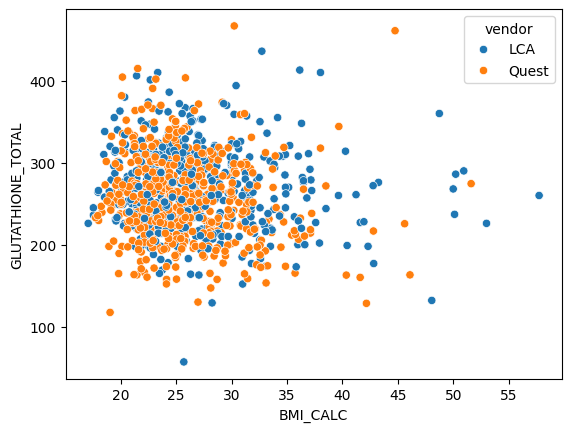

In [57]:
sns.scatterplot(data=labs_covar_dx, x='BMI_CALC',y='GLUTATHIONE_TOTAL', hue='vendor')
# HOORAY

## What about redundant lab tests?
Mostly interested in the ones that are potentially artifacts of data analysis or a mistake. For example if a column (i.e., lab test) was duplicated.
- TOTALNEUTROPHILSAB is a **shared** lab test
- TOTALNEUTROPHILS is a **shared** lab test
- NEUTROPHILSABSOLUTE: only appears for individuals who used *Quest*
- NEUTROPHIL_SEGS: *Quest*

<Axes: xlabel='NEUTROPHILSABSOLUTE', ylabel='TOTALNEUTROPHILSAB'>

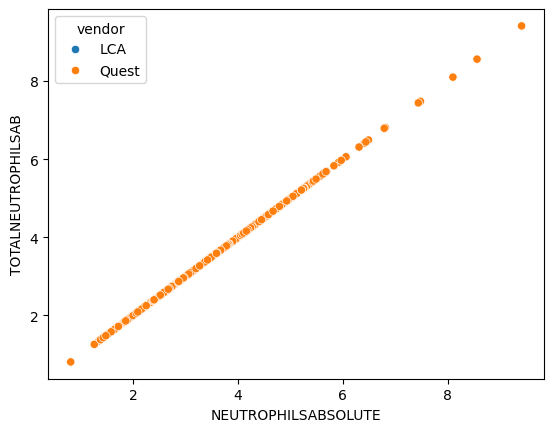

In [58]:
sns.scatterplot(data=labs_covar_dx, x='NEUTROPHILSABSOLUTE',y='TOTALNEUTROPHILSAB', hue='vendor')

<Axes: xlabel='NEUTROPHIL_SEGS', ylabel='TOTALNEUTROPHILS'>

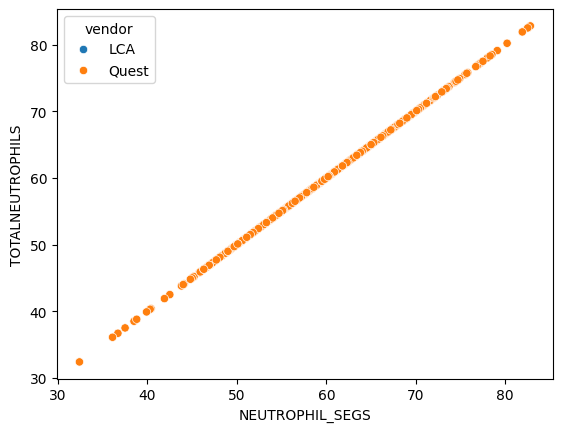

In [59]:
sns.scatterplot(data=labs_covar_dx, x='NEUTROPHIL_SEGS',y='TOTALNEUTROPHILS', hue='vendor')

Suspicious... it looks like `NEUTROPHIL_SEGS` and `NEUTROPHILSABSOLUTE` are just subsets of `TOTALNEUTROPHILS` and `TOTALNEUTROPHILSAB`, respectively for the folks that only used Quest. Booooo! We have duplicate columns. Let's make sure that's the case and then delete them. 
We do need to keep both `TOTALNEUTROPHILS` and `TOTALNEUTROPHILSAB` as one is a percentage of the WBC that are neutrophils and one is an absolute count.

In [60]:
(quest.TOTALNEUTROPHILS) == (quest.NEUTROPHIL_SEGS)

5       True
15      True
29      True
43      True
52      True
        ... 
2581    True
2583    True
2592    True
2602    True
2618    True
Length: 498, dtype: bool

In [61]:
(quest.NEUTROPHILSABSOLUTE) == (quest.TOTALNEUTROPHILSAB)

5       True
15      True
29      True
43      True
52      True
        ... 
2581    True
2583    True
2592    True
2602    True
2618    True
Length: 498, dtype: bool

Smh.... time for those columns to go!

In [62]:
labs_covar_dx.drop(columns=['NEUTROPHILSABSOLUTE', 'NEUTROPHIL_SEGS'], inplace=True)
not_offered_labcorp = not_offered_labcorp.drop(['NEUTROPHILSABSOLUTE', 'NEUTROPHIL_SEGS'])

In [63]:
len(not_offered_labcorp)

18

Also suspicious of platelet count... :o
- `PLATELETCOUNTTHOUSAND` is shared
- `PLATELETCOUNT` is in *Quest* only

<Axes: xlabel='PLATELETCOUNT', ylabel='PLATELETCOUNTTHOUSAND'>

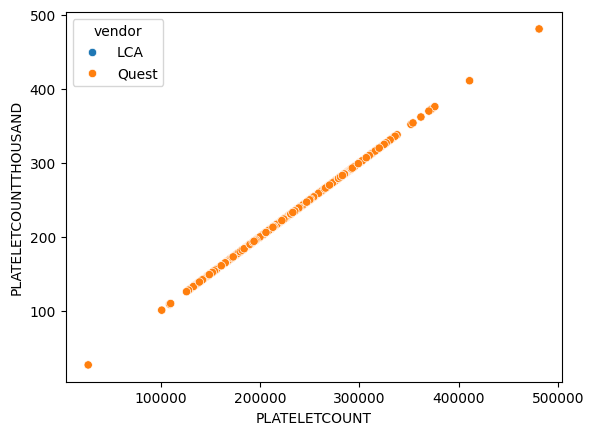

In [64]:
sns.scatterplot(data=labs_covar_dx, x='PLATELETCOUNT',y='PLATELETCOUNTTHOUSAND', hue='vendor')

In [65]:
(quest.PLATELETCOUNT) == (quest.PLATELETCOUNTTHOUSAND * 1000)

5       True
15      True
29      True
43      True
52      True
        ... 
2581    True
2583    True
2592    True
2602    True
2618    True
Length: 498, dtype: bool

In [66]:
labs_covar_dx.drop(columns='PLATELETCOUNT', inplace=True)
not_offered_labcorp = not_offered_labcorp.drop('PLATELETCOUNT')

In [67]:
len(not_offered_labcorp)

17

## Investigate labs that are supposedly "shared" but mostly one vendor
Example: something was offered by one one vendor in actuality but has one individual marked with a different vendor (like `EPA_AA` above).

`EPA_AA` is the ratio of the percentages of `EPA` and `ARACHIDONICACID`. Thus, it is a calculated metric and not the same as `EPA` or `ARACHIDONICACID` below. However, I wonder if it was derived for only the quest folks from the `EPA` and `ARACHIDONICACID` columns (which are offered by both quest and LCA). Some information on the tests can be found here: https://testdirectory.questdiagnostics.com/test/test-guides/TS_OmegaCheck/omegacheck

<Axes: xlabel='age', ylabel='EPA_AA'>

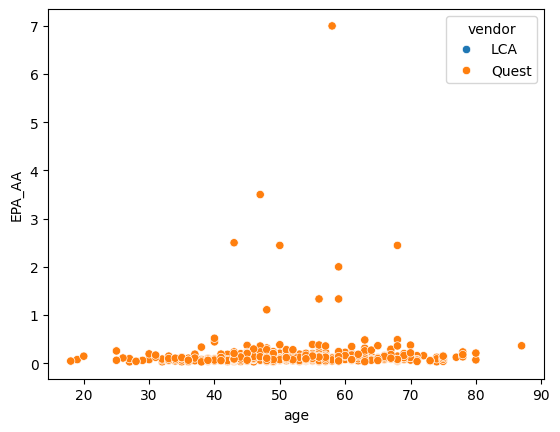

In [68]:
# Just picked age bc it was a continuous metric I could use to spread the observations
sns.scatterplot(data=labs_covar_dx, x='age',y='EPA_AA', hue='vendor')

In [69]:
labs_covar_dx[labs_covar_dx.EPA_AA.notna()].vendor.value_counts()

vendor
Quest    455
LCA        1
Name: count, dtype: int64

See only one person with this value came from LCA... weird. Let's test the hypothesis that `EPA_AA` was derived from `EPA` and `ARACHIDONICACID`.

In [70]:
quest.EPA_AA.describe()

count    455.000000
mean       0.166788
std        0.431422
min        0.026316
25%        0.065574
50%        0.095238
75%        0.147059
max        7.000000
Name: EPA_AA, dtype: float64

In [71]:
(quest.EPA / quest.ARACHIDONICACID).describe()

count    460.000000
mean       0.165804
std        0.429176
min        0.019048
25%        0.065535
50%        0.094737
75%        0.147059
max        7.000000
dtype: float64

Weird... first, the counts are different 467 compared to 473. Let's perform the calculation for only the folks that have non-null EPA_AA cells.

In [72]:
quest_EPA_test_df = quest[quest.EPA_AA.notnull()]

In [73]:
(quest_EPA_test_df.EPA_AA == (quest_EPA_test_df.EPA / quest_EPA_test_df.ARACHIDONICACID)).sum()

65

Looks like above, there are 67 people for which the calculation is exact.

In [74]:
(np.isclose(quest_EPA_test_df.EPA_AA, (quest_EPA_test_df.EPA / quest_EPA_test_df.ARACHIDONICACID))).sum()

453

Hmmm... there are 465 for which the values are close enough to just be FLOAT imprecision... but why isn't it 467? Who are the two people for which this isn't true?

In [75]:
EPA_AA_not_close = quest_EPA_test_df[~np.isclose(quest_EPA_test_df.EPA_AA, (quest_EPA_test_df.EPA / quest_EPA_test_df.ARACHIDONICACID))]

In [76]:
EPA_AA_not_close[['EPA_AA', 'EPA', 'ARACHIDONICACID']]

,EPA_AA,EPA,ARACHIDONICACID
2478,0.209524,1.0,5.8
2533,0.115702,1.0,6.2


Hmm... is the fact that they are both 1.0 an artifact? Let's look at the data. 

In [77]:
labs_covar_dx.EPA.describe()

count    2312.000000
mean        0.762976
std         0.454475
min         0.100000
25%         0.500000
50%         0.700000
75%         0.900000
max         5.100000
Name: EPA, dtype: float64

<Axes: xlabel='age', ylabel='EPA'>

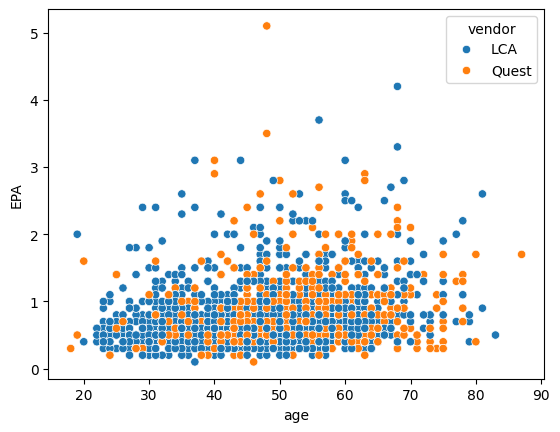

In [78]:
sns.scatterplot(data=labs_covar_dx, x='age',y='EPA', hue='vendor')

Looks like 1% is not rare or weird among our population. Indeed, according to Quest, their analytical sensitivity for EPA is 0.03%. 

## Drop EPA_AA and recalculate it 
I found a QUEST brochure that said ideally EPA/AA ratios would be under 0.2. Let's see what we find!

In [79]:
labs_covar_dx.drop(columns='EPA_AA', inplace=True)

In [80]:
labs_covar_dx.loc[:, 'EPA_AA'] = labs_covar_dx.loc[:, 'EPA'] / labs_covar_dx.loc[:, 'ARACHIDONICACID']

<Axes: xlabel='age', ylabel='EPA_AA'>

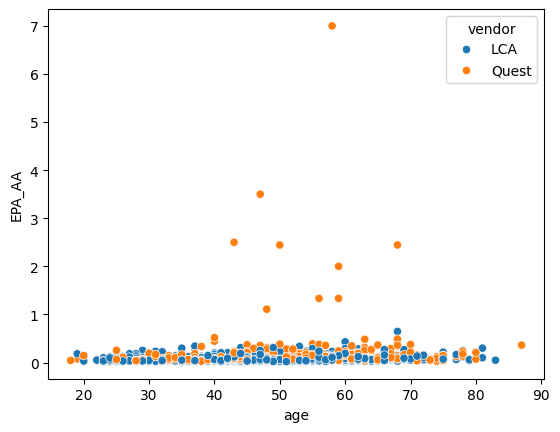

In [81]:
sns.scatterplot(data=labs_covar_dx, x='age',y='EPA_AA', hue='vendor')

In [82]:
labs_covar_dx.EPA_AA.describe() # Okay this falls under 0.2 for most people

count    2312.000000
mean        0.090219
std         0.199464
min         0.012346
25%         0.046512
50%         0.063636
75%         0.093333
max         7.000000
Name: EPA_AA, dtype: float64

## What is the difference between LDL_SIZE and LDLPEAKSIZE?
- `LDL_SIZE` by Labcorp has units in nm: https://files.labcorp.com/testmenu-d8/sample_reports/123810.pdf
- `LDLPEAKSIZE` by Quest is measured in Angstroms

Good news is that we can convert!

<Axes: xlabel='age', ylabel='LDLPEAKSIZE'>

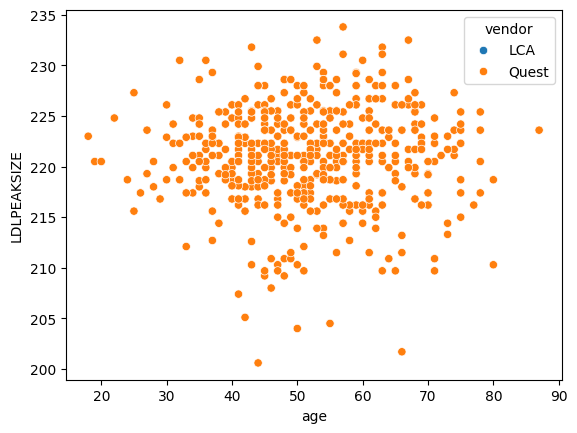

In [83]:
sns.scatterplot(data=labs_covar_dx, x='age',y='LDLPEAKSIZE', hue='vendor')

<Axes: xlabel='age', ylabel='LDL_SIZE'>

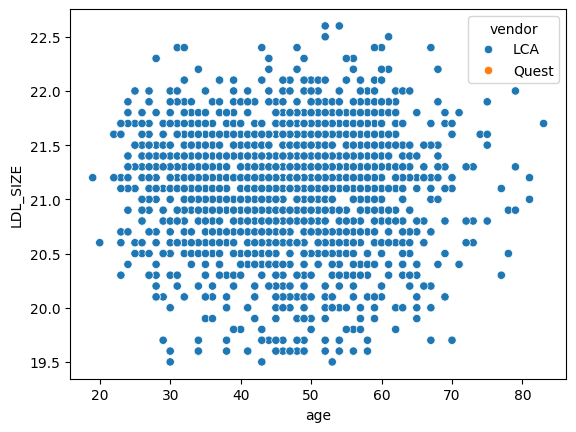

In [84]:
sns.scatterplot(data=labs_covar_dx, x='age',y='LDL_SIZE', hue='vendor')

Yep, these plots confirm the suspicion that the only difference was the unit. The y-axis is a factor 10 smaller for `LDL_SIZE`.

In [85]:
labs_covar_dx.loc[quest_mask, 'LDL_SIZE'] = labs_covar_dx.loc[quest_mask, 'LDLPEAKSIZE'] / 10

<Axes: xlabel='age', ylabel='LDL_SIZE'>

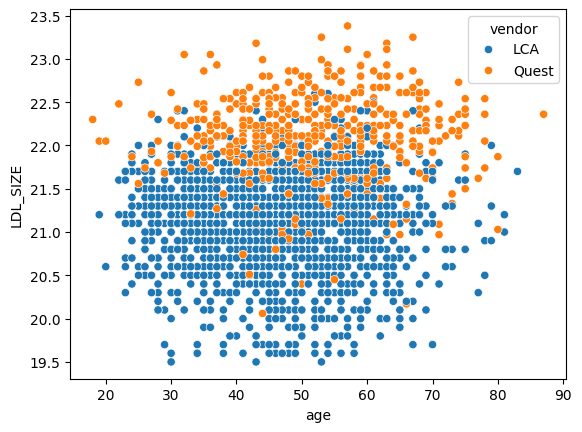

In [86]:
sns.scatterplot(data=labs_covar_dx, x='age',y='LDL_SIZE', hue='vendor')

In [87]:
labs_covar_dx.drop(columns='LDLPEAKSIZE', inplace=True)
not_offered_labcorp = not_offered_labcorp.drop('LDLPEAKSIZE')

In [88]:
not_offered_quest = not_offered_quest.drop('LDL_SIZE')

In [89]:
len(not_offered_quest)

8

In [90]:
# not_offered_quest

In [91]:
shared_labs.append('LDL_SIZE')

## Double check that there are no more duplicate/overlapping lab values that require dropping or transformation

In [92]:
labs_covar_dx[not_offered_labcorp].describe().T

,count,mean,std,min,25%,50%,75%,max
ANTIOXIDCAP_TOTAL,497.0,1301.041247,420.471429,576.2,988.500,1226.70,1511.80,3338.50
ARSENIC_BLOOD,497.0,2.909457,2.323150,2.0,2.000,2.00,3.00,31.00
BILIRUBIN_DIRECT,498.0,0.143373,0.065051,0.0,0.100,0.10,0.20,0.50
BILIRUBIN_INDIRECT,498.0,0.557831,0.229488,0.2,0.400,0.50,0.60,2.20
COPPER_RBC,497.0,0.653662,0.111698,0.4,0.580,0.63,0.70,1.35
HDLLARGE,498.0,6180.628514,1687.503008,2868.0,4940.750,5864.00,7151.25,12577.00
LACTICDEHYDROGENASE,498.0,137.574297,22.884794,69.0,121.000,135.00,151.00,232.00
LDLMEDIUM,498.0,243.734940,91.630667,48.0,175.250,229.00,292.75,697.00
MANGANESE_SERUM,498.0,0.633133,0.196771,0.5,0.500,0.60,0.70,3.10
MPV,498.0,9.723092,1.001532,6.4,9.100,9.60,10.30,13.30


In [93]:
labs_covar_dx[not_offered_quest].describe().T

,count,mean,std,min,25%,50%,75%,max
DPA,1852.0,1.090443,0.225784,0.1,0.9,1.1,1.2,2.3
HDLPARTICLENUMBER,1851.0,34.394057,5.980733,16.0,30.2,34.2,38.2,59.4
LINOLEIC_ACID,1852.0,25.817387,2.694320,14.6,24.1,25.8,27.6,34.5
LPIR_SCORE,1851.0,41.792545,19.621697,25.0,25.0,33.0,55.0,100.0
MAGNESIUM_SERUM,1839.0,2.025014,0.154634,1.3,1.9,2.0,2.1,3.4
OMEGA_3_TOTAL,1852.0,4.449946,1.224915,1.8,3.6,4.2,5.1,11.8
OMEGA_6_TOTAL,1852.0,39.940065,3.004055,23.7,38.1,40.2,41.9,50.2
OXLDL,1820.0,45.723626,14.816079,13.0,35.0,44.0,54.0,119.0


In [94]:
[x for x in shared_labs if 'OME' in x] # Looking for OMEGAs since there are labcorp specific tests

['OMEGA_6_OMEGA_3RATIO', 'OMEGA_3INDEX']

In [95]:
[x for x in shared_labs if 'HDL' in x] # Looking for HDL since there are labcorp AND quest specific tests

['TriglycerideHDLRatio', 'HDLCHOLDIRECT']

## Summary
1. **Dropped sparse columns** where over 90% of rows (samples/individuals) do not have a given lab measured. This is under the variable `bad`. Check which labs were dropped using `bad[bad]`. I also ended up dropping `VITAMIND2_25_OH` because there were only 7 legit observations for this lab test. 
3. Re-calculated the **QUICKI** because these values were extremely low *and* for some reason only Quest users had this index calculated. Values now look as they should for this. 
4. Identified **columns that were duplicated** in Quest vendor users. For example, a Quest user could have 60% of their white blood cells be neutrophils (normal) but this same percentage appears in both columns `NEUTROPHIL_SEGS` (Quest) and `TOTALNEUTROPHILS` (shared) because the former is a redundant column, where values are filled *ONLY for Quest users.* In total we **dropped 3 columns** where this was the case: `NEUTROPHIL_SEGS`, `NEUTROPHILSABSOLUTE`, `PLATELETCOUNT`.
5. Found instances where **units differed** between the two vendors. This was most prominent for `GLUTATHIONE_TOTAL` because the lab test had the same name. We recalculated this for the Quest rows using the molecular weight of Glutathione. This also happened for `LDL_SIZE` (Labcorp) and `LDLPEAKSIZE` (Quest). We dropped the Quest specific column, `LDLPEAKSIZE`, and converted `LDL_SIZE` for the Quest rows by converting Angstrom to nm.

In [96]:
# Save file for mediation with labs
labs_covar_dx.to_csv("data/clincal_chems_abx_users_clean.csv", index=False)